# Nguyễn Thành Trí - MSSV: 6451071079
## Bài 2: Mô hình hóa chất lượng rượu vang Red Wine Quality (Mục 4 trang 26)

In [1]:
# Nguyễn Thành Trí - MSSV: 6451071079
print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

def get_data_path(rel_path):
    candidates = [
        rel_path,
        os.path.join("..", rel_path),
        os.path.join("..", "..", rel_path),
        os.path.join("Dataset", os.path.basename(rel_path)),
        os.path.join("..", "Dataset", os.path.basename(rel_path)),
        os.path.join("..", "..", "Dataset", os.path.basename(rel_path))
    ]
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"Không tìm thấy file: {rel_path}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
- Đọc tập dữ liệu Red Wine Quality.
- Tính toán ma trận hệ số tương quan Pearson giữa 11 chỉ số hóa lý.
- Trực quan hóa bằng biểu đồ Heatmap của Seaborn và nhận xét.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập dữ liệu Red Wine Quality: (1599, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None


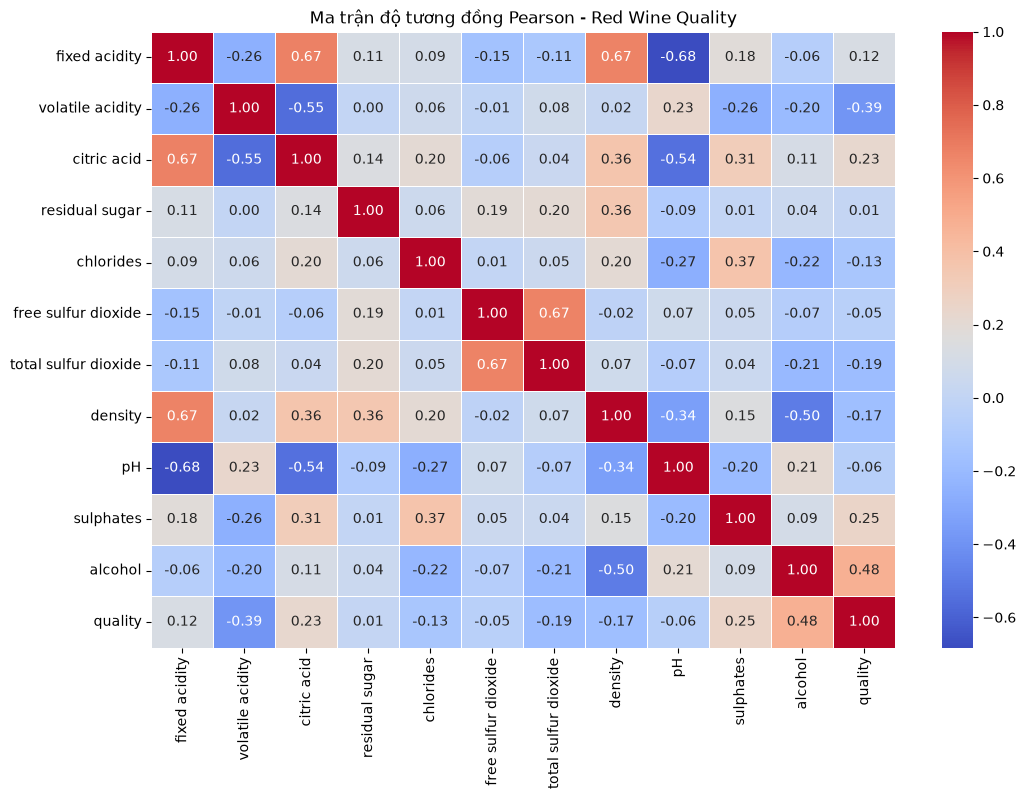


Nhận xét tương quan:
1. Cặp 'fixed acidity' và 'citric acid' có tương quan dương (r = 0.67), 'fixed acidity' và 'density' (r = 0.67) do tính chất hóa lý của nồng độ axit ảnh hưởng đến mật độ rượu.
2. Cặp 'free sulfur dioxide' và 'total sulfur dioxide' có tương quan dương (r = 0.67) do SO2 tự do là một phần của tổng SO2.
3. Cặp 'fixed acidity' và 'pH' có tương quan âm mạnh (r = -0.68) do pH tỷ lệ nghịch với nồng độ ion hydro của axit.
4. Không có cặp thuộc tính nào có hệ số tương quan vượt quá ngưỡng loại bỏ (|r| > 0.85). Do đó, toàn bộ 11 thuộc tính dự đoán được giữ nguyên.


In [2]:
# Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
wine_path = get_data_path("winequality-red.csv")
df_wine = pd.read_csv(wine_path)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập dữ liệu Red Wine Quality: {df_wine.shape}")
print(df_wine.info())

# Khảo sát ma trận tương quan Pearson giữa các thuộc tính đặc trưng
plt.figure(figsize=(12, 8))
corr_wine = df_wine.corr(method='pearson')
sns.heatmap(corr_wine, annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.title("Ma trận độ tương đồng Pearson - Red Wine Quality")
plt.show()

print()
print("Nhận xét tương quan:")
print("1. Cặp 'fixed acidity' và 'citric acid' có tương quan dương (r = 0.67), 'fixed acidity' và 'density' (r = 0.67) do tính chất hóa lý của nồng độ axit ảnh hưởng đến mật độ rượu.")
print("2. Cặp 'free sulfur dioxide' và 'total sulfur dioxide' có tương quan dương (r = 0.67) do SO2 tự do là một phần của tổng SO2.")
print("3. Cặp 'fixed acidity' và 'pH' có tương quan âm mạnh (r = -0.68) do pH tỷ lệ nghịch với nồng độ ion hydro của axit.")
print("4. Không có cặp thuộc tính nào có hệ số tương quan vượt quá ngưỡng loại bỏ (|r| > 0.85). Do đó, toàn bộ 11 thuộc tính dự đoán được giữ nguyên.")

### Câu 4: Tách các cột dữ liệu thành hai phần
- Phần 1 (X): Chứa 11 thuộc tính hóa lý đo đạc được (features).
- Phần 2 (y): Chứa thuộc tính quyết định 'quality' (target).

In [3]:
# Câu 4: Tách các cột dữ liệu thành hai phần
X = df_wine.drop(columns=['quality'])
y = df_wine['quality']

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập thuộc tính dự đoán (X): {X.shape}")
print(f"Kích thước thuộc tính quyết định (y): {y.shape}")
print(f"Danh sách các thang điểm chất lượng rượu (classes): {sorted(y.unique().tolist())}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập thuộc tính dự đoán (X): (1599, 11)
Kích thước thuộc tính quyết định (y): (1599,)
Danh sách các thang điểm chất lượng rượu (classes): [3, 4, 5, 6, 7, 8]


### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
- Kiểm tra kiểu dữ liệu của các thuộc tính dự đoán trong X.
- Áp dụng mã hóa One-Hot nếu phát hiện thuộc tính phân loại.

In [4]:
# Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
non_numeric_cols = X.select_dtypes(exclude=['number']).columns

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Các cột không phải dạng số: {list(non_numeric_cols)}")
if len(non_numeric_cols) == 0:
    print("Nhận xét: Toàn bộ 11 thuộc tính dự đoán của tập Red Wine Quality đều là dữ liệu số thực liên tục (float64). Do đó, không có thuộc tính phân loại cần áp dụng One-Hot Encoding, dữ liệu giữ nguyên để đưa vào mô hình.")
    X_encoded = X.copy()
else:
    X_encoded = pd.get_dummies(X, columns=non_numeric_cols, dtype=int)

print(f"Kích thước tập dữ liệu đặc trưng: {X_encoded.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Các cột không phải dạng số: []
Nhận xét: Toàn bộ 11 thuộc tính dự đoán của tập Red Wine Quality đều là dữ liệu số thực liên tục (float64). Do đó, không có thuộc tính phân loại cần áp dụng One-Hot Encoding, dữ liệu giữ nguyên để đưa vào mô hình.
Kích thước tập dữ liệu đặc trưng: (1599, 11)


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử
- Sử dụng hàm train_test_split chia 70% huấn luyện và 30% kiểm thử theo đề bài:
  `train_test_split(X, y, test_size=0.3, random_state=42)`

In [5]:
# Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện 70% và kiểm thử 30%
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Kích thước tập huấn luyện X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Kích thước tập kiểm thử X_test: {X_test.shape}, y_test: {y_test.shape}")

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Kích thước tập huấn luyện X_train: (1119, 11), y_train: (1119,)
Kích thước tập kiểm thử X_test: (480, 11), y_test: (480,)


### Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện và kiểm thử
- Sử dụng mô hình DecisionTreeClassifier với tiêu chí entropy (Information Gain).
- Đánh giá độ chính xác và ma trận nhầm lẫn (Confusion Matrix).
- Biểu diễn cấu trúc cây quyết định ID3.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
ID3 Decision Tree Accuracy: 0.5979

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.09      0.12      0.10        17
           5       0.71      0.67      0.69       195
           6       0.61      0.62      0.62       200
           7       0.46      0.46      0.46        61
           8       0.33      0.33      0.33         6

    accuracy                           0.60       480
   macro avg       0.37      0.37      0.37       480
weighted avg       0.61      0.60      0.60       480



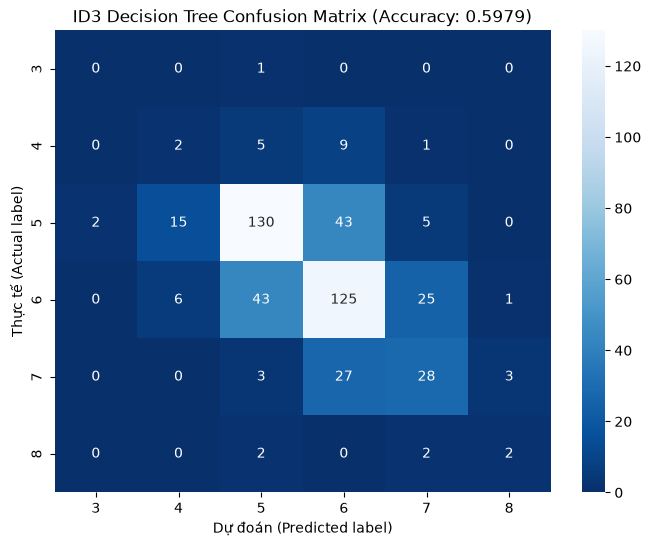

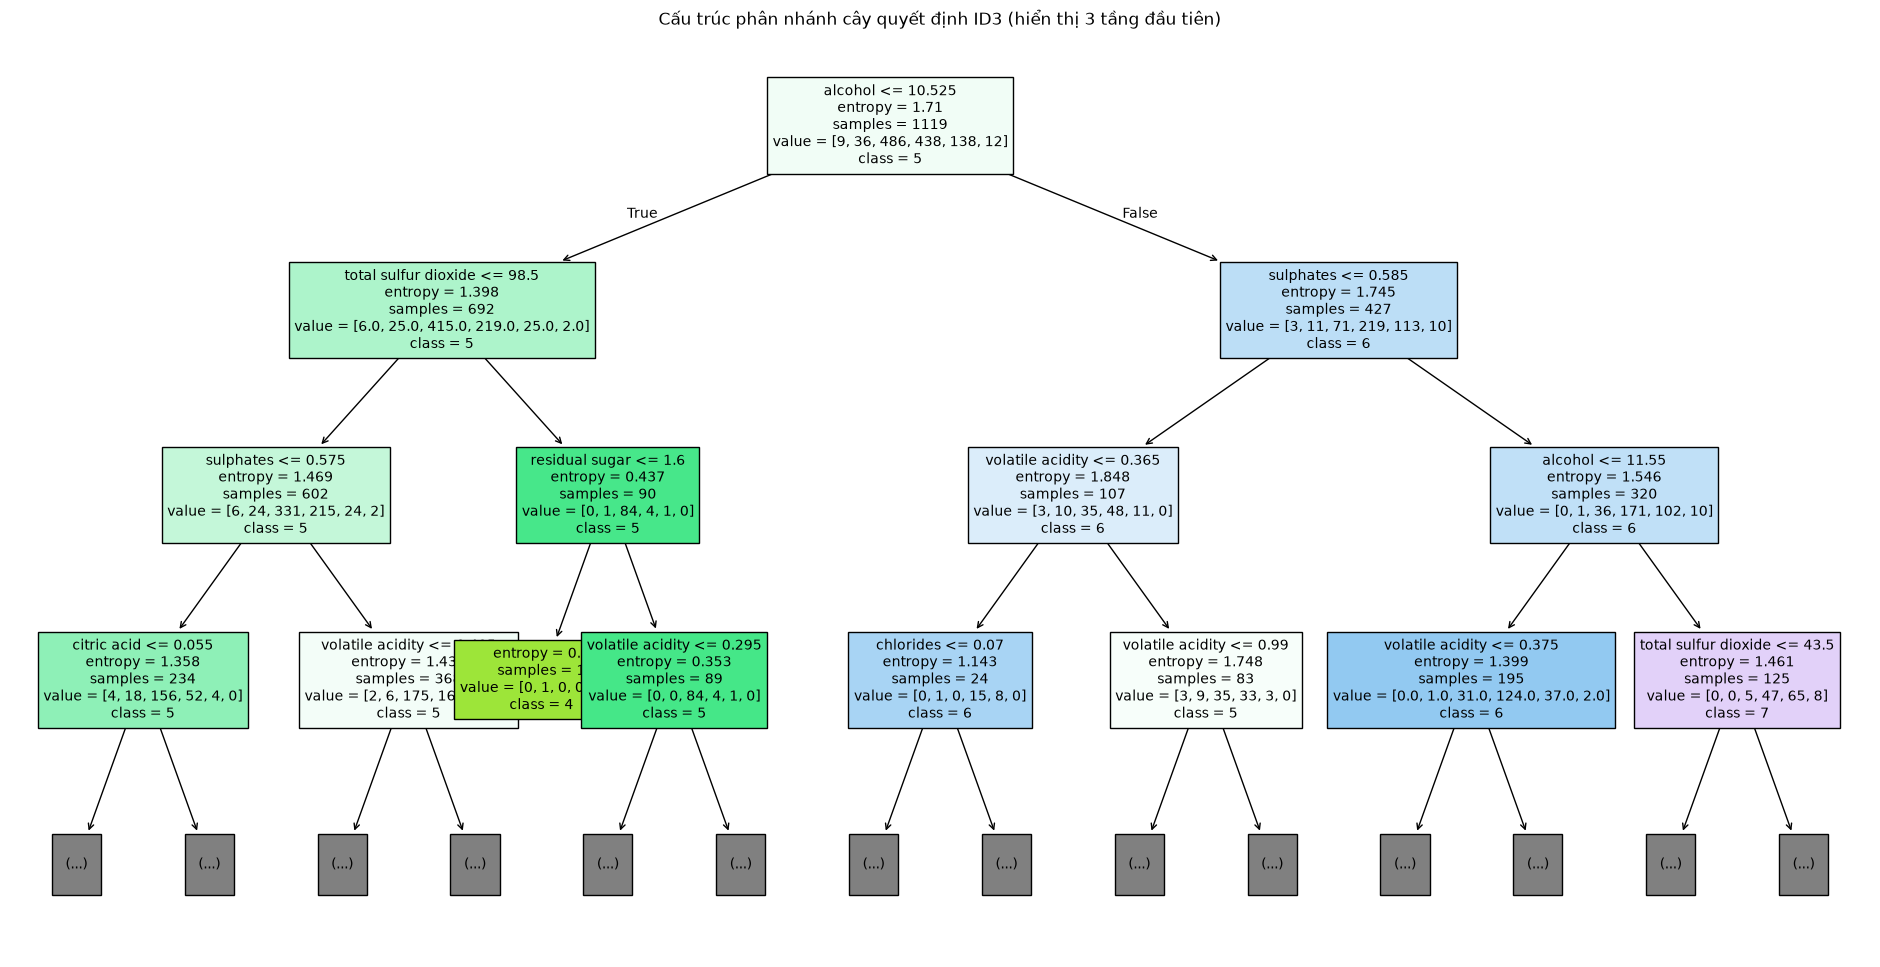

In [6]:
# Câu 7: Xây dựng cây ID3
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=42)
clf_id3.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"ID3 Decision Tree Accuracy: {id3_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, id3_pred, zero_division=0))

# Ma trận nhầm lẫn
id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", cmap="Blues_r",
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.xlabel("Dự đoán (Predicted label)")
plt.ylabel("Thực tế (Actual label)")
plt.title(f"ID3 Decision Tree Confusion Matrix (Accuracy: {id3_score:.4f})")
plt.show()

# Biểu diễn cây quyết định (hiển thị 3 tầng đầu để dễ quan sát)
plt.figure(figsize=(24, 12))
tree.plot_tree(clf_id3, max_depth=3, feature_names=X.columns.tolist(),
               class_names=[str(c) for c in clf_id3.classes_], filled=True, fontsize=10)
plt.title("Cấu trúc phân nhánh cây quyết định ID3 (hiển thị 3 tầng đầu tiên)")
plt.show()

### Câu 8: Xây dựng cây CART dựa trên dữ liệu huấn luyện và kiểm thử
- Sử dụng mô hình DecisionTreeClassifier với tiêu chí gini (Gini Impurity).
- Đánh giá độ chính xác và ma trận nhầm lẫn (Confusion Matrix).
- Biểu diễn cấu trúc cây quyết định CART.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
CART Decision Tree Accuracy: 0.5729

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.66      0.65      0.65       195
           6       0.57      0.60      0.59       200
           7       0.46      0.43      0.44        61
           8       0.33      0.17      0.22         6

    accuracy                           0.57       480
   macro avg       0.35      0.32      0.33       480
weighted avg       0.57      0.57      0.57       480



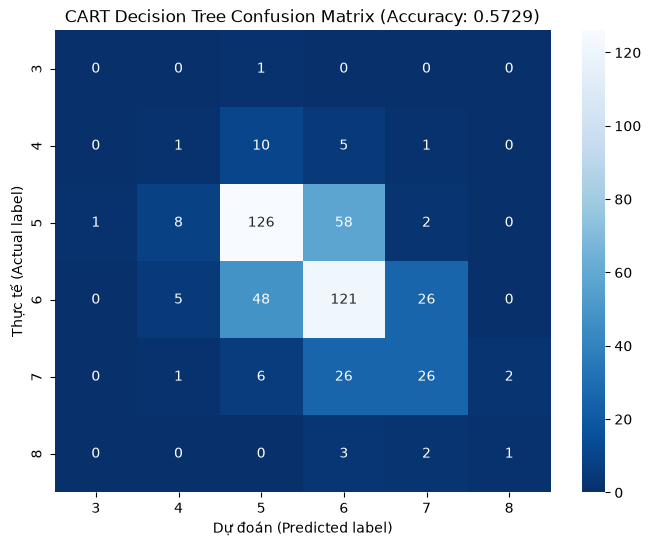

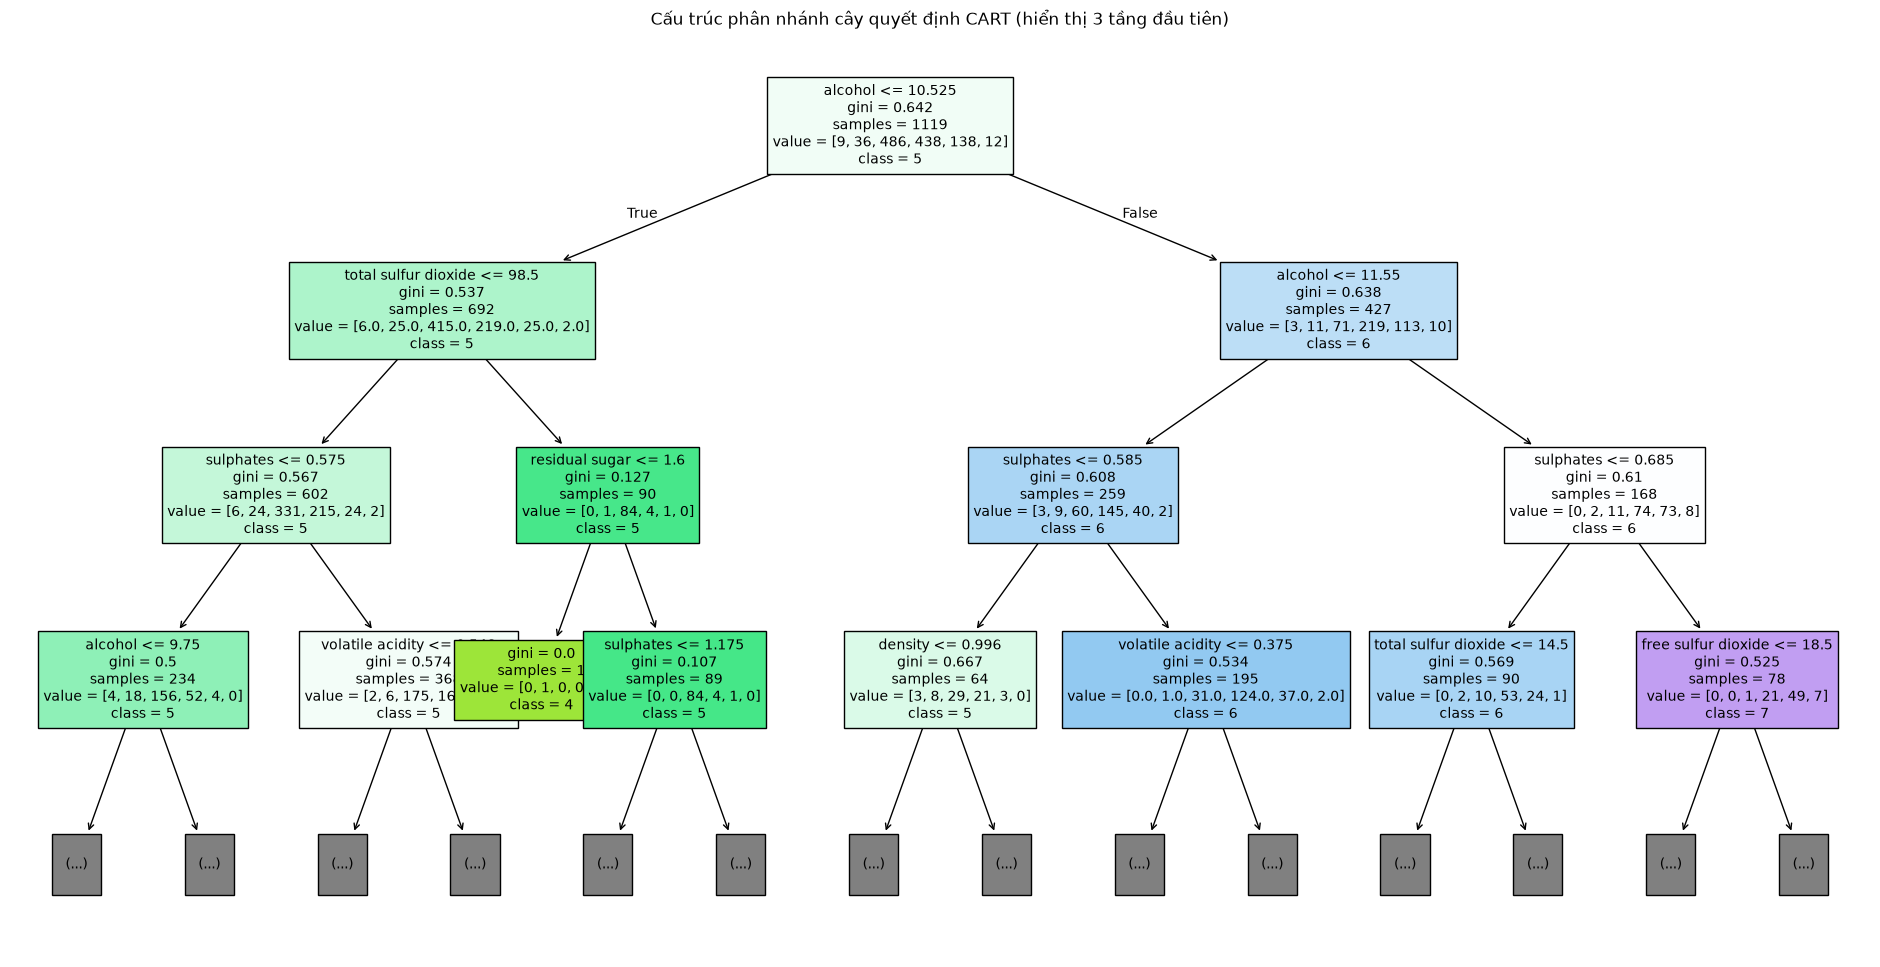

In [7]:
# Câu 8: Xây dựng cây CART
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=42)
clf_cart.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"CART Decision Tree Accuracy: {cart_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, cart_pred, zero_division=0))

# Ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", cmap="Blues_r",
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.xlabel("Dự đoán (Predicted label)")
plt.ylabel("Thực tế (Actual label)")
plt.title(f"CART Decision Tree Confusion Matrix (Accuracy: {cart_score:.4f})")
plt.show()

# Biểu diễn cây quyết định CART (hiển thị 3 tầng đầu để dễ quan sát)
plt.figure(figsize=(24, 12))
tree.plot_tree(clf_cart, max_depth=3, feature_names=X.columns.tolist(),
               class_names=[str(c) for c in clf_cart.classes_], filled=True, fontsize=10)
plt.title("Cấu trúc phân nhánh cây quyết định CART (hiển thị 3 tầng đầu tiên)")
plt.show()

### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes
- Sử dụng mô hình GaussianNB.
- Huấn luyện trên tập X_train, y_train và dự đoán trên tập X_test.
- Đánh giá độ chính xác và ma trận nhầm lẫn.

Họ tên: Nguyễn Thành Trí - MSSV: 6451071079
Naive Bayes Accuracy: 0.5417

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



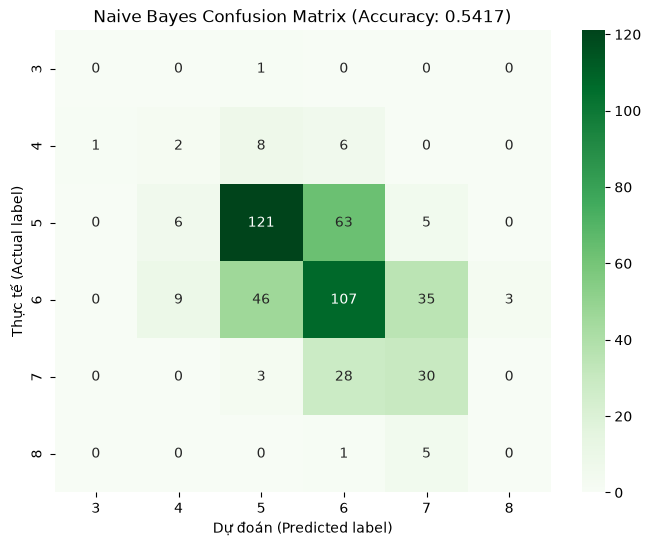

In [8]:
# Câu 9: Xây dựng mô hình Naïve Bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
bayes_pred = gnb.predict(X_test)
bayes_score = metrics.accuracy_score(y_test, bayes_pred)

print("Họ tên: Nguyễn Thành Trí - MSSV: 6451071079")
print(f"Naive Bayes Accuracy: {bayes_score:.4f}")
print()
print("Báo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, bayes_pred, zero_division=0))

# Ma trận nhầm lẫn
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.xlabel("Dự đoán (Predicted label)")
plt.ylabel("Thực tế (Actual label)")
plt.title(f"Naive Bayes Confusion Matrix (Accuracy: {bayes_score:.4f})")
plt.show()